# Week 1 · What is an information system?

Software is only one part of an information system. This week you meet the people, see the whole system working, and write your first lines of Python.

| | |
|---|---|
| **This week's question** | What is an information system, and who depends on it? |
| **Python you will learn** | values and types, names, arithmetic (`/`, `//`, `%`), text and numbers, f-strings, reading an error |
| **Principle 1** | **Clear names and units.** Code is read by people. A name should say what a value means and in what unit. |
| **Part you build** | the one-line offer summary that the coordinator reads |

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

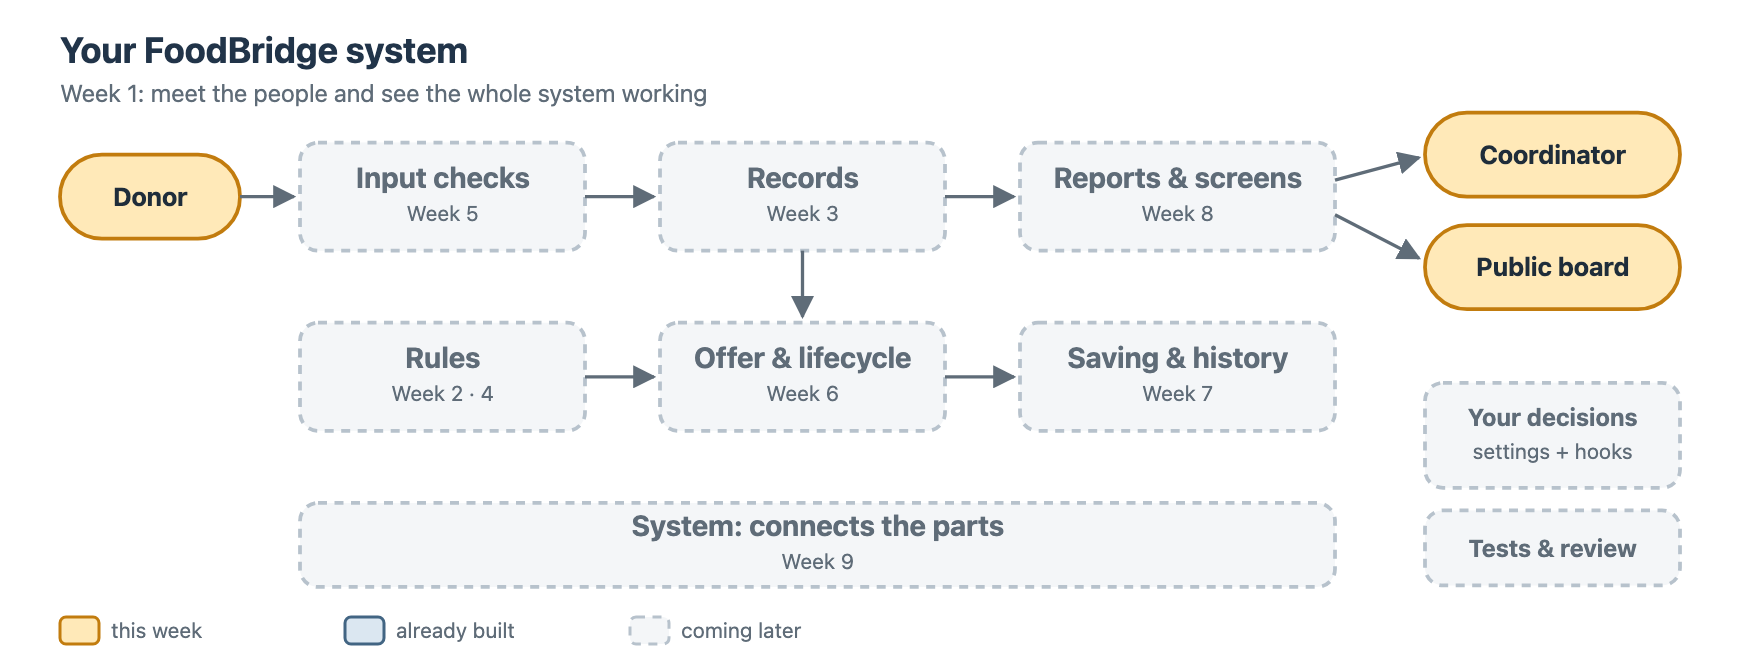

### The story so far

This is where the story starts. Campus FoodBridge helps food shops near campus pass spare food to people who need it, instead of throwing it away. One person, the coordinator, takes the phone calls and writes every offer in a paper notebook: donor, food, portions, and how soon it must be collected.

It is 7:30 on a busy morning. Sunrise Bakery calls: 30 portions of bread rolls. While the coordinator is still writing, a second shop calls, then a third. One number is crossed out and written again. Another is squeezed into the margin. By 8:00, nobody can say which portions belong to which donor, or whether the bread rolls are 30 portions or 80.

Paper cannot keep names and units clear. A system has to **show** every offer in one line that says exactly what each number means. That is this week's work.

🤔 **Predict:** three phone calls in ten minutes, all written by hand. What goes wrong **first**? Write one sentence before you open the answer.

**My answer:** …

<details><summary>Show a possible answer</summary>

There is no single right answer. Most mornings, the first failure is a **number with no clear owner**: a corrected figure is written over the old one, or a new offer is squeezed in without its donor's name. A number without a unit fails the same way: "30" alone does not say 30 *what*. This week you fix both problems: clear names, and a unit in every line.

</details>

## Before you start

1. **Save your own copy first.** In Colab click **Copy to Drive** (or choose **File → Save a copy in Drive**). Work in that copy, not in this original.
2. **Run the setup cell below** (click ▶). Run it again whenever Colab says the runtime restarted.
3. Work from top to bottom. Each section says how long it should take.

Levels: **⭐ core** is for everyone. **⭐⭐ stretch** is optional, for when you finish early.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.8"
_KIT_SHA = "41dafebb7ed52e8114e8bc10c2d9edb023f9aed5e823f1af14589289780e44f5"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


## Start with the destination (15 min)

By Week 10 you will have built every part of a small information system and made your own decisions about it. Let us see the finished system first. Run the next cell. It replays one fictional day.

In [ ]:
system = bridge.System()
system.run_day()

Read the output slowly. Food was **offered**, some offers were **refused at the door**, a coordinator **approved** or **rejected** offers, and volunteers **picked up** and **delivered** food.

Now look at what two different people see.

In [ ]:
print(system.report("coordinator"))

In [ ]:
print(system.report("public"))

### An information system is more than code

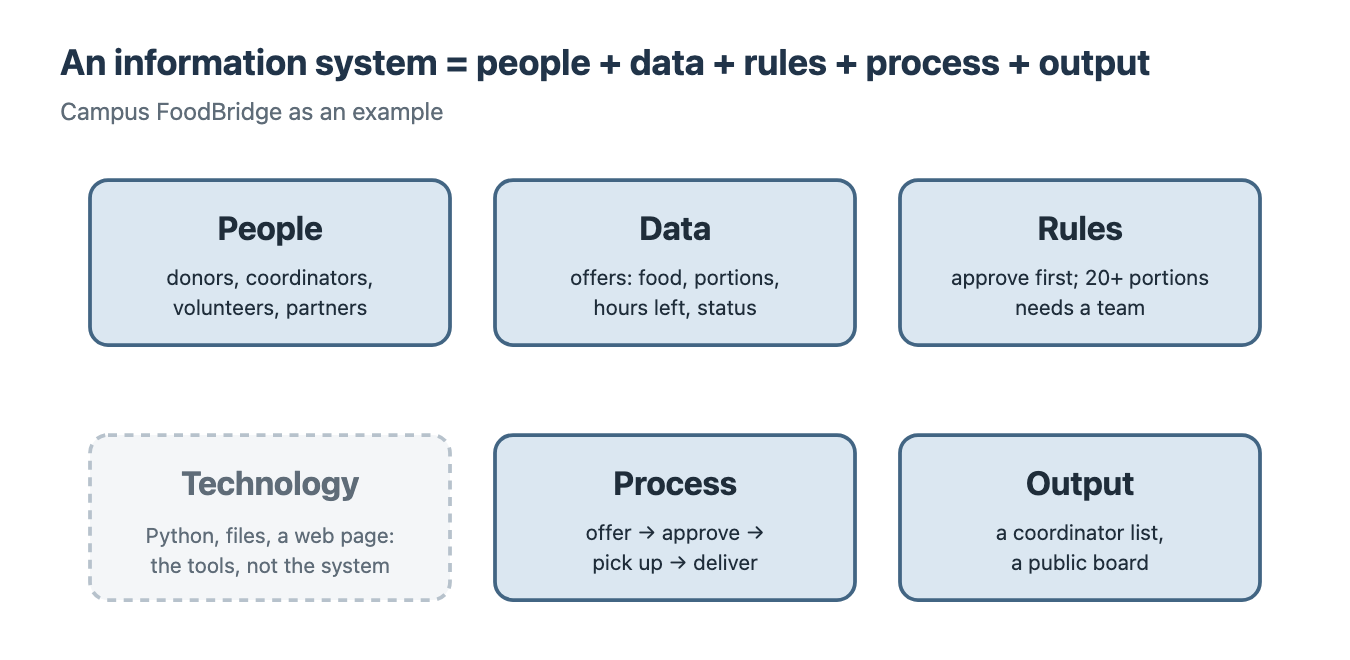

An **information system** is people, data, rules and a process working together to produce useful output. Technology (Python, files, a web page) is the tool. The system is only good if it helps the people.

🤔 **Look back at the outputs above and write short answers.**

1. Name three different **people** (roles) in this system.
2. Name three pieces of **data** the system keeps about an offer.
3. Find one **rule** the system followed. (Hint: why was an offer refused?)
4. Why does the public board show fewer columns than the coordinator view?

📝 **My notes:**

1. People:
2. Data:
3. A rule:
4. Why fewer columns:

## Session 1 · Learn and try: values, names and text (60–75 min)

Every idea below has the same rhythm: a short explanation, a tiny example, 🤔 **Predict** (write your guess *before* you run), then ✍️ **Try it**. In a Try-it you change the lines marked `TODO` and run the cell. The last lines print ✅ or ❌ at once, so you know whether you are right. You do not need to understand those check lines, and you never need to change them.

📖 If an idea feels new, [Python Basics](Python_Basics.ipynb) has a short extra exercise for each one.

### 1 · Values and types

Every program works with **values**: numbers, text, and true/false. Python keeps each value with a **type**, and the type decides what you can do with it.

In [ ]:
print(30)
print(2.5)
print("Bread rolls")
print(True)
print(type(30), type(2.5), type("Bread rolls"), type(True))

- `int` is a whole number, `float` is a number with a decimal point, `str` is text, `bool` is `True` or `False`.
- Text always has quotes. `"30"` is text that looks like a number; `30` is a number.

### ✍️ Try it 1 · Which type?

A phone shop keeps three values for each phone. 🤔 For each one, write the type you expect as text: `"int"`, `"float"`, `"str"` or `"bool"`. Then run the cell.

In [ ]:
price_riel = 450000
screen_inches = 6.5
phone_number = "012345678"

type_of_price = "?"          # TODO: "int", "float", "str" or "bool"
type_of_screen = "?"         # TODO
type_of_phone_number = "?"   # TODO

print("✅ price_riel" if type_of_price == type(price_riel).__name__ else "❌ price_riel: a whole number, or a decimal one?")
print("✅ screen_inches" if type_of_screen == type(screen_inches).__name__ else "❌ screen_inches: look for a decimal point")
print("✅ phone_number" if type_of_phone_number == type(phone_number).__name__ else "❌ phone_number: look at the quotes")

<details><summary>Why is a phone number text?</summary>

You never add or divide phone numbers, and as a number `012345678` would lose its first `0`. **The type follows the meaning, not the look.**

</details>

### 2 · Names and new values

A **name** (a variable) points to a value. `=` means *"let this name point to this value"*. It is not the `=` of mathematics: Python works out the **right side first**, then moves the name to the result. The old value is forgotten.

▶ [Animation: A name points to a value](https://loem-ms.github.io/programming-for-information-systems-site/assets/anim/anim_variables.html) (course website)

🤔 **Predict** what the cell prints, then run it.

In [ ]:
portions = 30
portions = portions + 12
print(portions)

**Prediction:** …  **Result:** …  **Why:** …

### ✍️ Try it 2 · Trace it on paper first

**Tracing** means following code line by line, the way the computer does, and writing down each value. Read the cell, but **do not run it yet**. On paper, work out the last value of `card_balance_riel` and of `total_riel`. Write your two answers in the first two lines, then run.

In [ ]:
my_card_balance_riel = 0     # TODO: your answer for card_balance_riel
my_total_riel = 0            # TODO: your answer for total_riel

card_balance_riel = 10000                      # a student canteen card
card_balance_riel = card_balance_riel - 4000   # lunch
card_balance_riel = card_balance_riel + 2000   # a top-up

fare_riel = 1500                               # one bus ticket
trips = 2
total_riel = fare_riel * trips
fare_riel = 2000                               # the price goes up after you paid

print("✅ card_balance_riel" if my_card_balance_riel == card_balance_riel else f"❌ card_balance_riel ends at {card_balance_riel}: go line by line, right side first")
print("✅ total_riel" if my_total_riel == total_riel else f"❌ total_riel is {total_riel}: it was worked out before fare_riel changed")

The second trace is a classic trap. `total_riel` was worked out **once**, with the old fare. Changing `fare_riel` later does not change it. A name points to a value, not to a formula.

### 3 · Arithmetic: which answer is useful?

| Operator | Meaning | `30 ? 4` |
|---|---|---|
| `+` `-` `*` | add, subtract, multiply | `34`, `26`, `120` |
| `/` | divide (always gives a float) | `7.5` |
| `//` | whole-number division | `7` |
| `%` | remainder (what is left over) | `2` |

In [ ]:
portions = 30
volunteers = 4
print(portions / volunteers)
print(portions // volunteers)
print(portions % volunteers)

🤔 A volunteer cannot carry half a portion. Which of the three answers is useful to the coordinator, and which is misleading? Write one sentence.

**My answer:** …

### ✍️ Try it 3 · Boxes of spring rolls

The canteen packs 50 spring rolls into boxes of 6. How many **full** boxes, and how many rolls are left over? Calculate with the names and `//` and `%`, not with numbers you worked out in your head.

In [ ]:
spring_rolls = 50
rolls_per_box = 6

full_boxes = 0     # TODO: use //
rolls_left = 0     # TODO: use %

print(f"{full_boxes} full boxes, {rolls_left} rolls left over")
print("✅ full_boxes" if full_boxes == spring_rolls // rolls_per_box else "❌ full_boxes: how many whole boxes? (//)")
print("✅ rolls_left" if rolls_left == spring_rolls % rolls_per_box else "❌ rolls_left: what is left after the full boxes? (%)")

Expected: `8 full boxes, 2 rolls left over`. 🤔 Now change `spring_rolls` to 60 and predict the new line before you run. If you typed `8` instead of a calculation, the check catches it.

### 4 · Text and numbers do not mix by accident

`+` adds numbers but **joins** text. Python refuses to join text and a number, because it cannot guess what you mean. `int()` turns text into a whole number; `str()` turns a number into text.

🤔 **Predict** the second line before you run.

In [ ]:
print(3 + 4)
print("3" + "4")
print(int("30") + 4)
print("Portions: " + str(30))

### ✍️ Try it 4 · A top-up typed as text

A phone top-up form saves the amount as **text**: `"5000"`. The shop adds a bonus of 1000 riel. Work out the new amount as a **number**, then build the receipt `Top-up: 6000 riel` with `str()`.

In [ ]:
amount_text = "5000"     # from the form: text
bonus_riel = 1000

total_riel = 0           # TODO: turn amount_text into a number, then add bonus_riel
receipt = "?"            # TODO: "Top-up: " + str(...) + " riel"

print(receipt)
print("✅ total_riel is a number" if total_riel == int(amount_text) + bonus_riel else "❌ total_riel: use int() on the text first, then add")
print("✅ receipt" if receipt == "Top-up: 6000 riel" else "❌ receipt should read exactly: Top-up: 6000 riel")

### 5 · f-strings: text with values and units

Joining with `+` and `str()` gets long. Put `f` before the quotes and write names inside `{ }`: Python fills in the values. Write the **unit after each number**, inside the text: `40 portions`, not just `40`.

▶ [Animation: Numbers, text and f-strings](https://loem-ms.github.io/programming-for-information-systems-site/assets/anim/anim_types.html) (course website)

In [ ]:
food = "Bananas"
portions = 40
hours_left = 3
print(f"{food}: {portions} portions, {hours_left} hours left")

### ✍️ Try it 5 · A line for the bus screen

A bus station screen shows one line per bus. Build this line with an f-string, using the three names, not the numbers:

`Phnom Penh to Kampot: 12 seats left, leaves in 40 minutes`

In [ ]:
route = "Phnom Penh to Kampot"
seats_left = 12
minutes_to_departure = 40

bus_line = "?"     # TODO: an f-string with the three names and their units

print(bus_line)
expected = route + ": " + str(seats_left) + " seats left, leaves in " + str(minutes_to_departure) + " minutes"
print("✅ bus_line" if bus_line == expected else "❌ compare your line with the example above, letter by letter")

Change `seats_left` to 5 and run again: your line follows the name. That is why you use names, not numbers, inside the `{ }`.

### 6 · Order matters, and errors are messages

Python runs a cell from top to bottom. In a notebook it also remembers names from cells you ran before, **in the order you ran them**. If something looks strange, use **Runtime → Restart session and run all** (Colab) or **Kernel → Restart & Run All** (Jupyter).

When Python cannot continue, it shows an **error**. Read the **last line** first: it names the problem.

🤔 **Predict:** what will the last line of the error say? Then remove the `#` at the start of the second line and run. Read the error, then put the `#` back so that *Run all* still works.

In [ ]:
print("This line runs.")
# print("Portions: " + 30)

`TypeError: can only concatenate str (not "int") to str` means: *you tried to join text and a number.* An error is not a failure. It is the program telling you exactly where to look.

### ✍️ Try it 6 · Repair the crash

Back to FoodBridge. A volunteer's line should print `Portions: 30`. Repair the crash in **two** ways: once with `str()`, once with an f-string.

In [ ]:
portions = 30
# print("Portions: " + portions)    # this line crashes: leave the # in place

with_str = "?"         # TODO: "Portions: " + str(...)
with_f_string = "?"    # TODO: an f-string

print(with_str)
print(with_f_string)
print("✅ both ways work" if with_str == with_f_string == "Portions: 30" else "❌ both lines should read exactly: Portions: 30")

Both ways work. The f-string is easier to read when a line has several values, so you use it for the rest of the course.

## Session 2 · Practise and judge (60–75 min)

You can name values, calculate with them and build lines of text. Session 2 uses the same skills on the coordinator's real request, with less help at each step. Then you judge code that runs but misleads.

### 🎫 This week's ticket

> **From:** the coordinator · **To:** you
> "I read offers on my phone, often while I walk between shops. A paper note like *30 bread 5* means nothing an hour later. Give me **one clear line per offer**: the ID, the food, the portions, the hours left and the donor, with a unit after every number."

| | |
|---|---|
| **Who reads it** | the coordinator, on a phone, in a hurry |
| **Inputs** | `offer_id`, `food`, `portions` (a whole number), `hours_left` (a whole number), `donor` |
| **Format** | `ID · food · N portions · N hours left · from donor` |
| **Done when** | your line passes the four checks in Session 3, with a unit after every number |

| `offer_id` | `food` | `portions` | `hours_left` | `donor` | The line |
|---|---|---|---|---|---|
| `"F001"` | `"Bread rolls"` | `30` | `5` | `"Sunrise Bakery"` | `F001 · Bread rolls · 30 portions · 5 hours left · from Sunrise Bakery` |
| `"F002"` | `"Fried rice boxes"` | `18` | `2` | `"Campus Canteen"` | `F002 · Fried rice boxes · 18 portions · 2 hours left · from Campus Canteen` |
| `"F004"` | `"Vegetable curry with rice"` | `12` | `4` | `"Lotus Cafe"` | `F004 · Vegetable curry with rice · 12 portions · 4 hours left · from Lotus Cafe` |

### ✏️ Model it on paper first

Before you code, draw the coordinator's phone on paper: a tall, narrow box about 35 characters wide. Write the F001 line inside it, the way the coordinator will see it.

1. Circle every number. Write its unit next to the circle.
2. The line does not fit on one row. Where would you break it? Which part would you never cut?
3. Show your sketch to a classmate for five seconds, then hide it. Can they say how many portions there are, and how many hours are left?

📝 **My sketch:** (describe it, or add a photo) · **Numbers and their units:** … · **Where I would break the line:** … · **What my classmate remembered:** …

### 🧩 The ladder: the same skill twice, with less help

#### 🧩 Ladder 1 · Put the lines in order

The offer form gives the portions as text, and 4 volunteers share them. Click the lines into order (one line does not belong), then press **Check**.

In [ ]:
bridge.parsons("share_portions")

*On the course website the puzzle does not run. Open the notebook in Colab, or write the letters in order in your notes.*

<details><summary>Show the answer</summary>

```python
portions = int("30")
volunteers = 4
each = portions // volunteers
left_over = portions % volunteers
print(f"{each} portions each, {left_over} left over")
```

The line that does not belong is `each = portions / volunteers`. `/` always gives a float: `30 / 4` is `7.5`, and nobody can carry half a portion.

</details>

#### 🧩 Ladder 2 · From a blank cell: the number that arrived as text

Riverside Restaurant phones in an offer of noodle soup. The form saves the portions as **text**: `"25"`. Then the restaurant adds 5 more portions. Write the code that works out the real total as a **number**, and builds the line `Noodle soup: 30 portions` with an f-string. No hints this time.

In [ ]:
food = "Noodle soup"
portions_text = "25"     # from the form: text
extra_portions = 5

total_portions = 0       # your code
line = "?"               # your code

print(line)
print("✅ total_portions" if total_portions == int(portions_text) + extra_portions else "❌ total_portions: turn the text into a number first, then add")
print("✅ line" if line == "Noodle soup: 30 portions" else "❌ line should read exactly: Noodle soup: 30 portions")

<details><summary>Show a possible answer</summary>

```python
total_portions = int(portions_text) + extra_portions
line = f"{food}: {total_portions} portions"
```

The trap is the type. `"25" + 5` crashes, and `"25" + "5"` joins the text into `"255"`. Convert with `int()` *before* you add.

</details>

### ⚖️ Good or risky?

You asked an AI assistant: *"Write Python to share 30 portions between 4 volunteers."* It gave you **Version A**. A classmate wrote **Version B**. Both run.

**Version A** (from the AI assistant)

```python
x = 30
y = 4
print(x / y)
```

**Version B**

```python
portions = 30
volunteers = 4
portions_each = portions // volunteers
left_over = portions % volunteers
print(f"Each volunteer carries {portions_each} portions; {left_over} portions are left over.")
```

Use **Principle 1 (clear names and units)** to judge them.

1. Which version would a coordinator trust, and why?
2. Version A prints `7.5`. What could go wrong if a volunteer acts on that number?
3. Is Version B *finished*? Name one thing it still does not tell you.

📝 **My judgement:** 1. … 2. … 3. …

<details><summary>Instructor's view</summary>

1. **Version B.** Its names say what each number means, and its output has units. A new volunteer can read it without asking anyone.
2. `7.5` has no unit and no meaning. A volunteer may pack 7 or 8 portions each, and then the last person gets too few. Nobody knows that 2 portions are left over.
3. Version B does not say **who** takes the 2 left-over portions. A real coordinator needs a rule for that, and a person must choose it.

Version A is not *wrong* Python; it is a risky **information** design. Code that runs is not the same as a system people can trust.

</details>

## Session 3 · Build, check, decide (60 min)

Practice is finished. Now build the line from the ticket. The coordinator reads it on a phone, often in a hurry. It must be short, but it must not lose meaning: a number without a unit is a guess.

In [ ]:
offer_id = "F001"
food = "Bread rolls"
portions = 30
hours_left = 5
donor = "Sunrise Bakery"

# TODO: build one line like
#   F001 · Bread rolls · 30 portions · 5 hours left · from Sunrise Bakery
summary = "?"

print(summary)

### Check your line

A check is a small piece of code that tests a promise. Run it. Each ❌ tells you what is missing. You do not need to understand the check's code yet.

In [ ]:
checks = {
    "has the ID": offer_id in summary,
    "has the food": food in summary,
    "portions with the unit": f"{portions} portions" in summary,
    "hours with the unit": f"{hours_left} hours" in summary,
}
for promise, kept in checks.items():
    print("✅" if kept else "❌", promise)

🤔 Change `portions` to `18` in your build cell and run both cells again. Does your line follow? If it still says 30, you typed a number instead of a name. Change it back to 30 when you are done.

### 👀 See your line inside the system

The finished system prints a similar line for every offer. The loop below is a preview of Week 3: you do not need to understand it yet. Run it and compare with your own line.

In [ ]:
system = bridge.System()
system.run_day(show=False)
for offer in system.offers:
    print(offer.describe())

🤔 The system's line shows the **status**, but not the hours left or the donor. Yours shows more. Which is better for a coordinator on a phone, and which is better for a donor?

**My answer:** …

### 🧭 Your decision · name your system

Every week you make one decision about **your** system and write it in a **decision log**. This week's decision is small: the name people see at the top of every screen.

A name in CAPITAL letters, like `SYSTEM_NAME`, is a **setting**: a value a person chooses, written once at the top, that the system reads. From Week 2 your settings change how the system behaves. The `{ }` part hands your setting to the system; you meet this shape (a dictionary) in Week 3.

In [ ]:
SYSTEM_NAME = "Campus FoodBridge"     # 🧭 change this to your own name for the system

my_system = bridge.System(settings={"SYSTEM_NAME": SYSTEM_NAME})
my_system.run_day(show=False)
print(my_system.report("public"))

📝 **Decision log · Week 1**

| | |
|---|---|
| **My choice** | |
| **An alternative** | |
| **Why I chose it** | |
| **Who is affected / the tradeoff** | |

A name is a small decision, but the habit matters. From next week, your decisions change what the system does.

### ⭐⭐ Stretch · a line for a tiny screen

Some volunteers use very old phones that show only 30 characters. Write a shorter version of your summary, using the names from your build cell. `len(text)` tells you how many characters a text has. Which information did you keep, and why?

In [ ]:
short_summary = "?"     # ⭐⭐ your shorter line: 30 characters or fewer

print(short_summary, "·", len(short_summary), "characters")
print("✅ fits a tiny screen" if short_summary != "?" and len(short_summary) <= 30 else "❌ not yet: write a line of 30 characters or fewer")

**What I kept, and why:** …

## Finish

- [ ] I saved my own copy in Drive, ran the finished system and answered the four questions about it.
- [ ] I wrote a prediction before running, and all six ✍️ Try-its show ✅.
- [ ] I finished both steps of the ladder and wrote my judgement of Version A.
- [ ] My offer summary passes all four checks.
- [ ] I named my system and filled in my first decision log.

### Research 1 · A real information system (5%)

Choose an information system you have used: school registration, a bus or ticket app, a library, a hospital queue, a mobile-money app. Find out:

1. **Who** uses it (at least two different roles)?
2. **What data** does it keep?
3. **One rule** it follows (for example, "a book is due after 14 days").
4. **One thing that could go wrong**, and who would be hurt.

Use at least one source and name it. You may use an AI assistant to explore, but then check one of its claims yourself and say how you checked. Write about half a page in your own words. Bring one finding to the **Week 2 class warm-up**. Submit by email to submit.progmis@gmail.com; the deadline and file name will be announced in class.

**What you can now do:** give values clear names with their units, trace code line by line, calculate with `//` and `%`, turn text into numbers and back, and build the one-line summary the coordinator reads.

**Next week's problem:** your line can *describe* an offer, but it cannot *decide* anything. Should an offer wait, go to one volunteer, or need a team? Next week you write those rules, and you choose the numbers yourself.

⬅ **Start:** the course home page · **Next:** [Week 2 · Rules and decisions](Week_02.ipynb) ➡